# 4. PPO Training Curves

Trains PPO on the real packet-capture trace (`data/pcap_trace.csv`) and
plots a learning curve against the reference heuristics, so you can see
PPO actually improving over training rather than just a single before/after
number.

This trains for 60,000 timesteps in ~1-2 minutes on CPU. It's enough to
see PPO overtake the naive heuristics; it is **not** enough to match
`queue_proportional` -- `examples/train_ppo.py --timesteps 300000` is the
one to run for a real result (see README.md).

In [1]:
import sys, os
REPO_ROOT = os.path.abspath("..")
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)
os.chdir(REPO_ROOT)

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from stable_baselines3 import PPO
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.vec_env import VecNormalize

from carla_gym.env import CarlaGymEnv
from carla_gym.core.trace_traffic import TraceTrafficGenerator
from examples.random_agent_test import policy_max, policy_queue_proportional, policy_random
from examples.train_ppo import rollout

plt.rcParams["figure.dpi"] = 100

TRACE_PATH = "data/pcap_trace.csv"
assert os.path.exists(TRACE_PATH), (
    "Run `python scripts/prepare_trace.py --in data/output1.csv --out data/pcap_trace.csv` first."
)
NUM_NODES = 16
SEED = 0

In [2]:
def make_env(seed):
    def _f():
        traffic = TraceTrafficGenerator(nodes=list(range(NUM_NODES)), csv_path=TRACE_PATH,
                                        target_load=110.0, seed=seed)
        env = CarlaGymEnv(topology="grid", num_nodes=NUM_NODES, max_steps=100,
                          bandwidth_budget=0.5, traffic=traffic, seed=seed)
        return Monitor(env)
    return _f

venv = make_vec_env(lambda: make_env(SEED)(), n_envs=4, seed=SEED)
venv = VecNormalize(venv, norm_obs=False, norm_reward=True)

model = PPO("MlpPolicy", venv, n_steps=512, batch_size=256, gamma=0.95,
           learning_rate=3e-4, ent_coef=0.0, seed=SEED, verbose=0)

## Train in chunks, evaluating on held-out seeds after each chunk

Held-out seeds (1000+) are never used for training, so this is a genuine
generalization check at each checkpoint, not a training-set score.

In [3]:
eval_env = make_env(0)()
test_seeds = range(1000, 1008)
CHUNK = 10_000
N_CHUNKS = 6

ppo_fn = lambda e, o: model.predict(o, deterministic=True)[0]
curve = []
t0 = time.time()
for i in range(N_CHUNKS):
    model.learn(total_timesteps=CHUNK, reset_num_timesteps=False)
    mean_r, std_r = rollout(eval_env, ppo_fn, test_seeds, steps=100)
    timesteps_so_far = (i + 1) * CHUNK
    curve.append({"timesteps": timesteps_so_far, "reward_mean": mean_r, "reward_std": std_r})
    print(f"[{time.time()-t0:5.1f}s] timesteps={timesteps_so_far:6d}  "
         f"held-out reward={mean_r:+.3f} +/- {std_r:.3f}")

curve = pd.DataFrame(curve)

[  1.6s] timesteps= 10000  held-out reward=-0.198 +/- 0.011
[  3.3s] timesteps= 20000  held-out reward=-0.171 +/- 0.041
[  4.9s] timesteps= 30000  held-out reward=-0.130 +/- 0.058
[  6.4s] timesteps= 40000  held-out reward=-0.111 +/- 0.063
[  8.0s] timesteps= 50000  held-out reward=-0.098 +/- 0.061
[  9.5s] timesteps= 60000  held-out reward=-0.099 +/- 0.058


## Baseline heuristics on the same held-out seeds

In [4]:
baselines = {}
for name, fn in [("queue_proportional", policy_queue_proportional),
                 ("max_bandwidth", policy_max),
                 ("random", lambda e, o: policy_random(e, o, np.random.default_rng()))]:
    m, sd = rollout(eval_env, fn, test_seeds, steps=100)
    baselines[name] = m
    print(f"{name:20s} reward={m:+.3f} +/- {sd:.3f}")

queue_proportional   reward=-0.038 +/- 0.040
max_bandwidth        reward=-0.113 +/- 0.041
random               reward=-0.148 +/- 0.031


## Learning curve vs. baselines

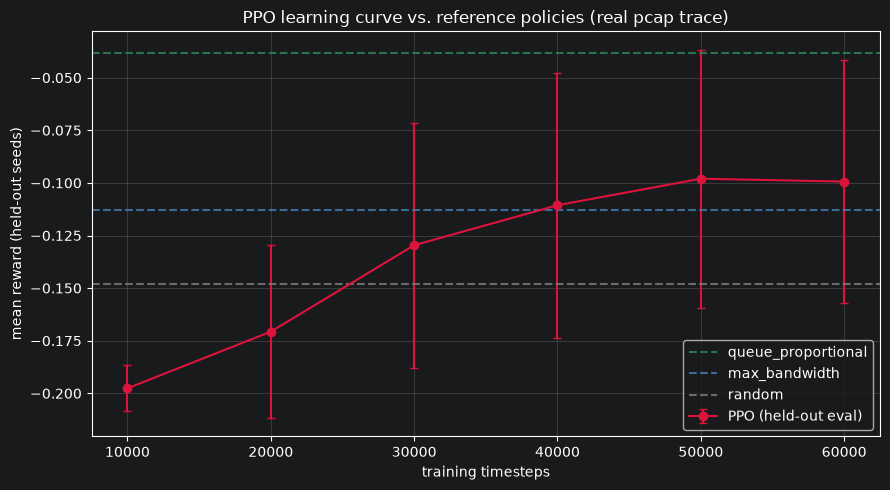

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(curve["timesteps"], curve["reward_mean"], yerr=curve["reward_std"],
           marker="o", color="crimson", label="PPO (held-out eval)", capsize=3)

colors = {"queue_proportional": "seagreen", "max_bandwidth": "steelblue", "random": "gray"}
for name, val in baselines.items():
    ax.axhline(val, linestyle="--", color=colors.get(name, "black"), label=name, alpha=0.8)

ax.set_xlabel("training timesteps")
ax.set_ylabel("mean reward (held-out seeds)")
ax.set_title("PPO learning curve vs. reference policies (real pcap trace)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
final = curve.iloc[-1]
print(f"After {int(final['timesteps'])} timesteps, PPO reaches {final['reward_mean']:+.3f}.")
beats = [name for name, v in baselines.items() if final["reward_mean"] > v]
print(f"That already beats: {beats if beats else 'none yet'}")
print()
print("Run `python examples/train_ppo.py --trace data/pcap_trace.csv --nodes 16 \\")
print("    --load 110 --budget 0.5 --timesteps 300000` for a full training run.")

After 60000 timesteps, PPO reaches -0.099.
That already beats: ['max_bandwidth', 'random']

Run `python examples/train_ppo.py --trace data/pcap_trace.csv --nodes 16 \
    --load 110 --budget 0.5 --timesteps 300000` for a full training run.
